# Demo: from a scanned judgment to a flagged timeline

Runs the whole pipeline on three anonymized Court of Appeal judgments from `data/sample/`. CAMeLBERT needs a GPU: on Colab/Kaggle it is used automatically, on a laptop the demo falls back to a TF-IDF matcher. On a GPU runtime (Colab/Kaggle) it uses CAMeLBERT; on a laptop it falls back to a TF-IDF matcher, so the demo still runs.

Flags are **review candidates for a person to look at, not verdicts**.

In [1]:
import datetime as dt, json, os, sys
from pathlib import Path
from IPython.display import HTML, display
sys.path.insert(0, str(Path('..').resolve()))
from lawcoherence import analyse, preprocess
from lawcoherence.timeline import plot_timelines

BACKEND = os.environ.get('LAW_BACKEND')      # 'camelbert' or 'tfidf'; unset = CAMeLBERT if a GPU is present (Colab/Kaggle), else tfidf
if not BACKEND:
    import torch
    BACKEND = 'camelbert' if torch.cuda.is_available() else 'tfidf'
DATA = Path('..') / 'data' / 'sample'
index = json.loads((DATA / 'index.json').read_text())
raw = {k: (DATA / f'{k}.txt').read_text(encoding='utf-8') for k in index}
rtl = lambda s: HTML(f"<div dir='rtl' style='font-size:15px;line-height:1.7'>{s}</div>")
list(index.items())

[('case_A',
  {'ruling_date': '2019-11-11',
   'outcome': 'appeal rejected, first-instance judgment upheld',
   'court': 'Civil Court of Appeal, Mount Lebanon'}),
 ('case_B',
  {'ruling_date': '2017-11-19',
   'outcome': 'appeal rejected, first-instance judgment upheld',
   'court': 'Civil Court of Appeal, Mount Lebanon'}),
 ('case_C',
  {'ruling_date': '2016-01-06',
   'outcome': 'one appeal rejected as inadmissible, one accepted, judgment reversed in part',
   'court': 'Civil Court of Appeal, Mount Lebanon'})]

## 1. OCR cleanup

Raw Tesseract output (left) has stray page numbers, stamps, bidi marks and hard line wraps. `clean_ocr` unifies digits and dates, drops junk lines and re-joins wrapped lines into paragraphs.

In [2]:
k = 'case_A'
display(rtl('<b>raw (first 12 lines)</b><br>' + '<br>'.join(raw[k].splitlines()[:12])))
paras = preprocess.clean_ocr(raw[k])
display(rtl('<b>cleaned (first 4 paragraphs)</b><br><br>' + '<br><br>'.join(paras[:4])))
print(f'{len(raw[k].splitlines())} lines -> {len(paras)} paragraphs')

116 lines -> 33 paragraphs


## 2-5. Run every stage on all three judgments

In [3]:
results = {}
for k, v in index.items():
    results[k] = analyse(raw[k], dt.date.fromisoformat(v['ruling_date']), name=f"{k}: {v['outcome']}", backend=BACKEND)
    r = results[k]
    print(f"{k}: {len(r['paras'])} paragraphs | {len(r['clauses'])} reasoning clauses | {len(r['parts']['operative'])} operative orders | "
          f"{len(r['events'])} dated events ({sum(e.imputed for e in r['events'])} imputed)")

case_A: 33 paragraphs | 14 reasoning clauses | 4 operative orders | 11 dated events (0 imputed)
case_B: 41 paragraphs | 17 reasoning clauses | 5 operative orders | 10 dated events (0 imputed)
case_C: 26 paragraphs | 8 reasoning clauses | 5 operative orders | 6 dated events (1 imputed)


### Ruling-to-reasoning linking (CAMeLBERT)

Each operative order is linked to the reasoning clauses closest to it in meaning. Scores are cosine similarities after centring on the judgment's own mean vector.

In [4]:
r = results['case_A']
for l in r['links']:
    best = l['links'][0]
    display(rtl(f"<b>[{l['kind']}]</b> {l['order']}<br><span style='color:#566174'>closest clause {best['clause']} "
                f"(score {best['score']:.2f}):</span> {r['clauses'][best['clause']]['text'][:230]}…"))

### Date extraction and imputation

Events are read with the words around each date. A date the OCR destroyed becomes an undated slot and is placed inside the interval allowed by the neighbouring stages (hollow marker in the plot).

In [5]:
for k, r in results.items():
    print(k)
    for e in r['events']:
        tag = f'  <- imputed, between {e.lo} and {e.hi}' if e.imputed else ''
        print(f'   {e.date}  {e.kind}{tag}')

case_A
   2013-08-02  underlying agreement
   2016-02-29  underlying agreement
   2016-08-03  underlying agreement
   2017-02-28  underlying agreement
   2017-07-31  submission
   2018-10-14  first-instance judgment
   2018-11-21  appeal filed
   2019-04-11  submission
   2019-06-24  hearing closed
   2019-11-16  ruling (signature line)
   2020-02-29  underlying agreement
case_B
   2006-12-09  petition
   2016-03-15  first-instance judgment
   2016-06-27  appeal filed
   2016-11-21  petition
   2016-12-10  underlying agreement
   2017-03-12  court decision
   2017-07-31  expert report
   2017-08-20  court decision
   2017-09-24  court decision
   2017-11-19  ruling (signature line)
case_C
   2013-06-05  first-instance judgment
   2013-07-25  appeal filed
   2014-02-05  court decision
   2014-03-24  submission
   2014-06-11  submission  <- imputed, between 2013-07-25 and 2015-04-29
   2015-04-29  hearing closed


### Timeline graphs

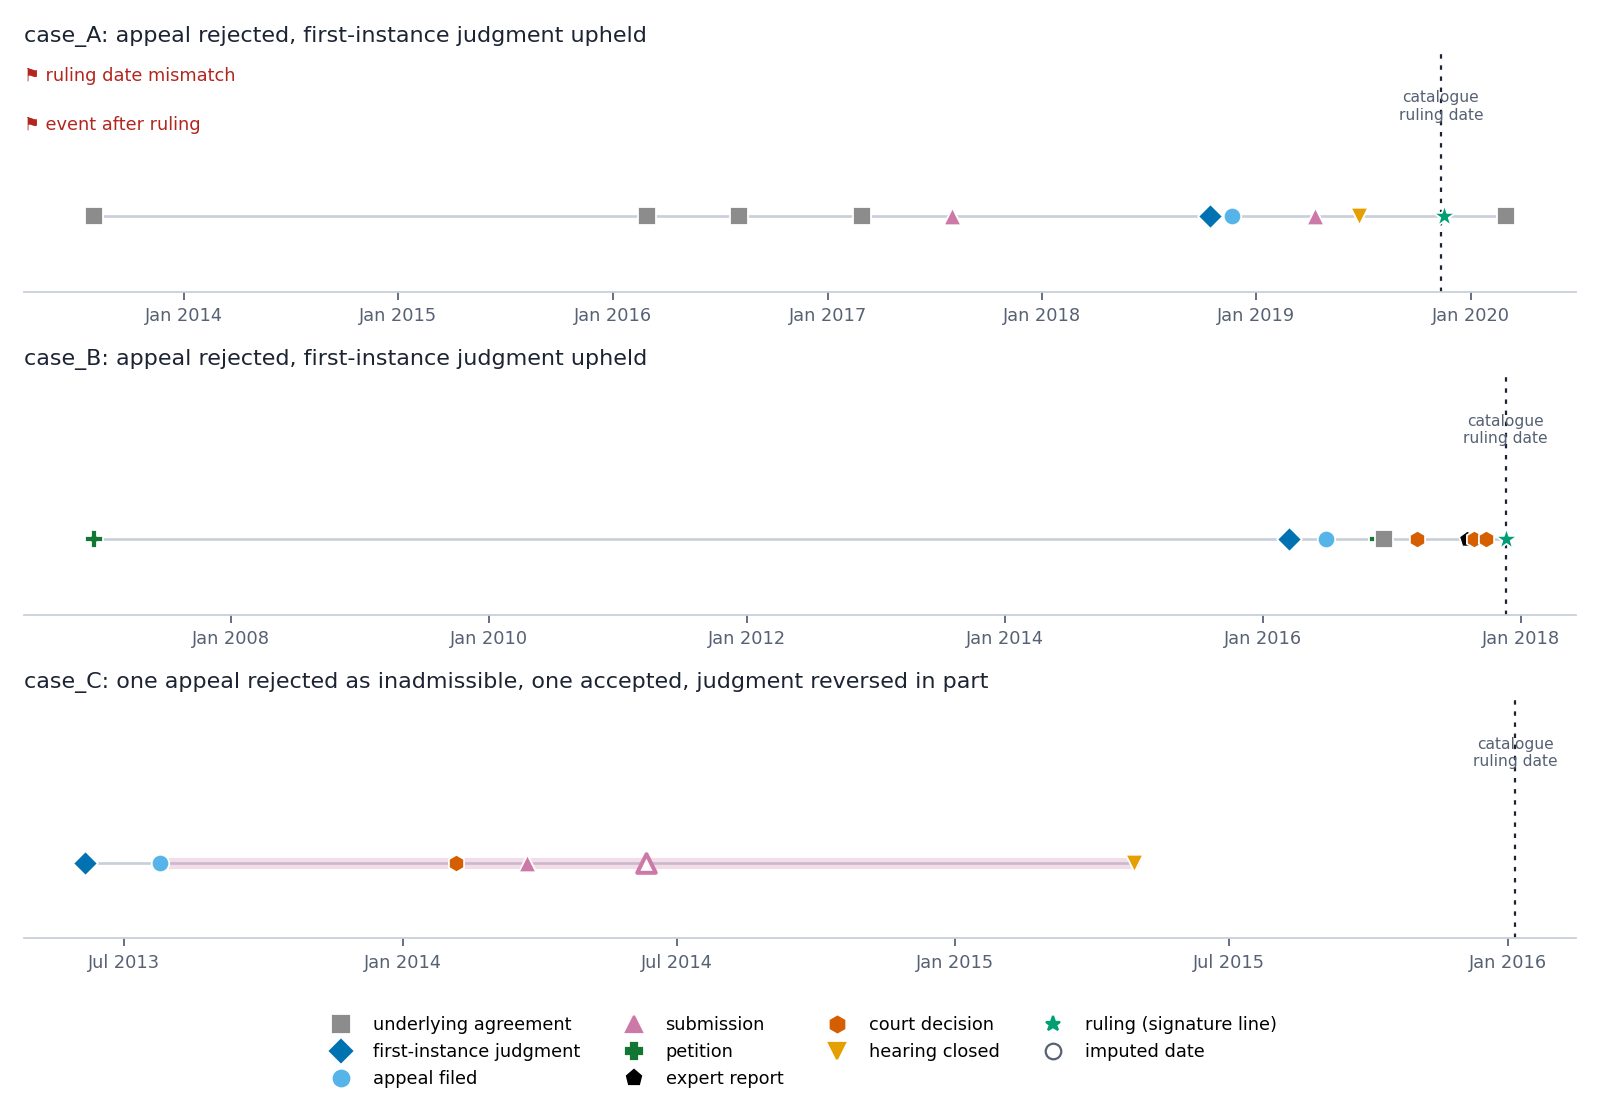

In [6]:
plot_timelines([dict(name=r['name'], graph=r['graph'], flags=r['flags']) for r in results.values()], '../docs/timeline_example.png')
from IPython.display import Image
Image('../docs/timeline_example.png')

## Flagged output

In [7]:
for k, r in results.items():
    print(f"\n{k}")
    for f in r['flags']:
        print(f"   [{f['level']:5}] {f['flag']:30} {f['why']}")


case_A
   [check] ruling date mismatch           signature line says 2019-11-16, catalogue says 2019-11-11 (+5 days)
   [check] event after ruling             2020-02-29 is after the ruling (2019-11-11)
   [info ] long gap                       440 days between 2017-07-31 and 2018-10-14

case_B

case_C
   [info ] imputed date                   no readable date; placed at 2014-06-11 between 2013-07-25 and 2015-04-29
